# Xenium Data Preprocessing and Quality Control

This notebook handles the initial preprocessing steps for Xenium spatial transcriptomics data:
- Loading data from h5 files
- Quality control metrics
- Filtering low-quality cells and genes
- Normalization
- Highly variable gene selection
- Dimensionality reduction (PCA, UMAP)

**Input:** Raw h5 files from Xenium platform

**Output:** Preprocessed AnnData object ready for downstream analysis

In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import spatialdata as sd
from spatialdata_io import xenium
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import h5py
import warnings
# === XENIUM_TISSUE dispatch ===
import os, sys, importlib
from pathlib import Path as _Path
_repo = _Path(_os.environ.get("XENIUM_ANALYSIS_ROOT", _Path.cwd().parent)).resolve()
if str(_repo) not in sys.path:
    sys.path.insert(0, str(_repo))
_TISSUE = os.environ.get("XENIUM_TISSUE", "pancreas")
_markers = importlib.import_module(f"scripts.tissue_markers.{_TISSUE}")
print(f"[tissue dispatch] XENIUM_TISSUE={_TISSUE}")
# === end XENIUM_TISSUE dispatch ===
warnings.filterwarnings('ignore')

# Rapids GPU-accelerated single-cell ops (drop-in for sc.pp.scale/pca/neighbors).
# UMAP and leiden intentionally stay on CPU per CLAUDE.md (rapids/cuML UMAP
# produced extreme outliers; cugraph leiden has dask-cuda 24.12 vs dask 2026.1
# version drift).
import rapids_singlecell as rsc
import cupy as cp

# Enable TF32 / Tensor Cores on B200 (compute capability 10.0).
if torch.cuda.is_available():
    torch.set_float32_matmul_precision('high')
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    print(f"GPU: {torch.cuda.get_device_name(0)} (TF32 enabled, "
          f"matmul_precision={torch.get_float32_matmul_precision()})")

# Set plotting parameters
sc.settings.verbosity = 3
sc.settings.set_figure_params(dpi=80, facecolor='white', frameon=False)
sns.set_style('whitegrid')

from matplotlib import rcParams

FIGSIZE = (3, 3)
rcParams["figure.figsize"] = FIGSIZE

print(f"Scanpy version: {sc.__version__}")
print(f"Squidpy version: {sq.__version__}")
print(f"rapids_singlecell version: {rsc.__version__}")


## 1. Define Paths and Parameters

In [ ]:
import os
from pathlib import Path

SAMPLE_ID   = os.environ.get("XENIUM_SAMPLE_ID", "0041323")
RAW_DIR     = Path(os.environ.get("XENIUM_RAW_DIR", "../data/raw"))
ZARR_PATH   = RAW_DIR / f"{SAMPLE_ID}.zarr"
OUTPUT_DIR  = Path(os.environ.get("XENIUM_OUTPUT_DIR",  f"../data/processed/{SAMPLE_ID}"))
FIGURES_DIR = Path(os.environ.get("XENIUM_FIGURES_DIR", f"../figures/{SAMPLE_ID}/01_preprocessing"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# QC defaults aligned with 10x Xenium 5k tutorial (2026) + empirical tightening.
# Original config (MIN_COUNTS=5, MAX_COUNTS=1500) produced library-size-dominated UMAPs
# because low-count spikes survived and the upper tail was truncated.
MIN_GENES  = int(os.environ.get("XENIUM_MIN_GENES",  20))   # drop empty cells
MIN_COUNTS = int(os.environ.get("XENIUM_MIN_COUNTS", 50))   # drop spike cells
MAX_COUNTS_QUANTILE = float(os.environ.get("XENIUM_MAX_COUNTS_Q", 0.98))  # adaptive; set post-qc
MIN_CELLS  = int(os.environ.get("XENIUM_MIN_CELLS",  100))  # 10x recommendation
LEIDEN_RES = float(os.environ.get("XENIUM_LEIDEN_RES", 1.5))

print(f"Sample:    {SAMPLE_ID}")
print(f"Zarr in:   {ZARR_PATH}")
print(f"H5ad out:  {OUTPUT_DIR}")
print(f"Figures:   {FIGURES_DIR}")
print(f"Filters:   min_genes={MIN_GENES} min_counts={MIN_COUNTS} "
      f"max_counts=quantile({MAX_COUNTS_QUANTILE}) min_cells={MIN_CELLS}")
print(f"Leiden:    resolution={LEIDEN_RES}")


## 2. Load Xenium Data

Load the Xenium data from output directory. Xenium data includes:
- Gene expression matrix
- Cell spatial coordinates
- Cell metadata

In [ ]:
if not ZARR_PATH.exists():
    raise FileNotFoundError(
        f"Expected zarr at {ZARR_PATH}. Run notebooks/00_ingest_xenium.ipynb first."
    )
print(f"Loading {ZARR_PATH} ...")
sdata = sd.read_zarr(ZARR_PATH)
print(f"Loaded: tables={list(sdata.tables.keys())}")
sdata

In [6]:
adata = sdata.tables["table"]
adata

AnnData object with n_obs × n_vars = 330758 × 5101
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

In [7]:
adata.obs

,cell_id,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,nucleus_count,segmentation_method,region,z_level,cell_labels
0,aaaaadcp-1,456,0,0,0,0,0,456,62.405940,31.383595,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,1
1,aaaacooc-1,381,0,0,0,0,0,381,74.778753,30.209532,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,2
2,aaaadpja-1,352,0,0,0,0,0,352,47.368908,19.688126,2.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,3
3,aaaaebih-1,513,0,0,0,0,0,513,61.051252,21.178282,2.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,4
4,aaaaeefg-1,228,0,0,0,0,0,228,42.582345,26.055157,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330753,oiliekap-1,6,0,0,0,0,0,6,11.379375,7.315313,1.0,Segmented by nucleus expansion of 5.0µm,cell_circles,5.0,330754
330754,oiliepdb-1,13,0,0,0,0,0,13,21.810470,21.810470,1.0,Segmented by nucleus expansion of 5.0µm,cell_circles,6.0,330755
330755,oilifjic-1,21,0,0,0,0,0,21,23.345782,23.345782,1.0,Segmented by nucleus expansion of 5.0µm,cell_circles,5.0,330756
330756,oilihgji-1,34,0,0,0,0,0,34,19.326876,19.326876,1.0,Segmented by nucleus expansion of 5.0µm,cell_circles,4.0,330757


In [8]:
adata.obsm["spatial"]

array([[1176.27307129,  716.39752197],
       [1162.71313477,  773.7902832 ],
       [1182.67492676,  708.17834473],
       ...,
       [2873.16381836, 2796.3359375 ],
       [2912.65820312, 2839.5859375 ],
       [2913.76220703, 2843.70166016]], shape=(330758, 2))

## 3. Initial Quality Control Metrics

In [9]:
# Calculate QC metrics
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

cprobes = (
    adata.obs["control_probe_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
cwords = (
    adata.obs["control_codeword_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
print(f"Negative DNA probe count % : {cprobes}")
print(f"Negative decoding count % : {cwords}")

Negative DNA probe count % : 0.0012807100352189276
Negative decoding count % : 0.0005027086119550931


In [ ]:
# Pre-filter QC histograms. Also stash a copy of the QC obs columns
# so cell 15 can OVERLAY the before/after distributions on a single plot.
# Without an overlay, the bulk of the data is so similar that before/after
# panels look visually identical even when ~7% of cells are dropped.
_pre_filter_qc = adata.obs[["total_counts", "n_genes_by_counts",
                             "cell_area", "nucleus_area"]].copy()

fig, axs = plt.subplots(1, 4, figsize=(25, 6))
axs[0].set_title(f"Total transcripts per cell (n={adata.n_obs:,})")
sns.histplot(adata.obs["total_counts"], kde=False, ax=axs[0])
axs[1].set_title(f"Unique transcripts per cell (n={adata.n_obs:,})")
sns.histplot(adata.obs["n_genes_by_counts"], kde=False, ax=axs[1])
axs[2].set_title(f"Area of segmented cells (n={adata.n_obs:,})")
sns.histplot(adata.obs["cell_area"], kde=False, ax=axs[2])
axs[3].set_title(f"Nucleus ratio (n={adata.n_obs:,})")
sns.histplot(adata.obs["nucleus_area"] / adata.obs["cell_area"], kde=False, ax=axs[3])
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'qc_histo_before_filtering.png', dpi=300, bbox_inches='tight')
plt.show()


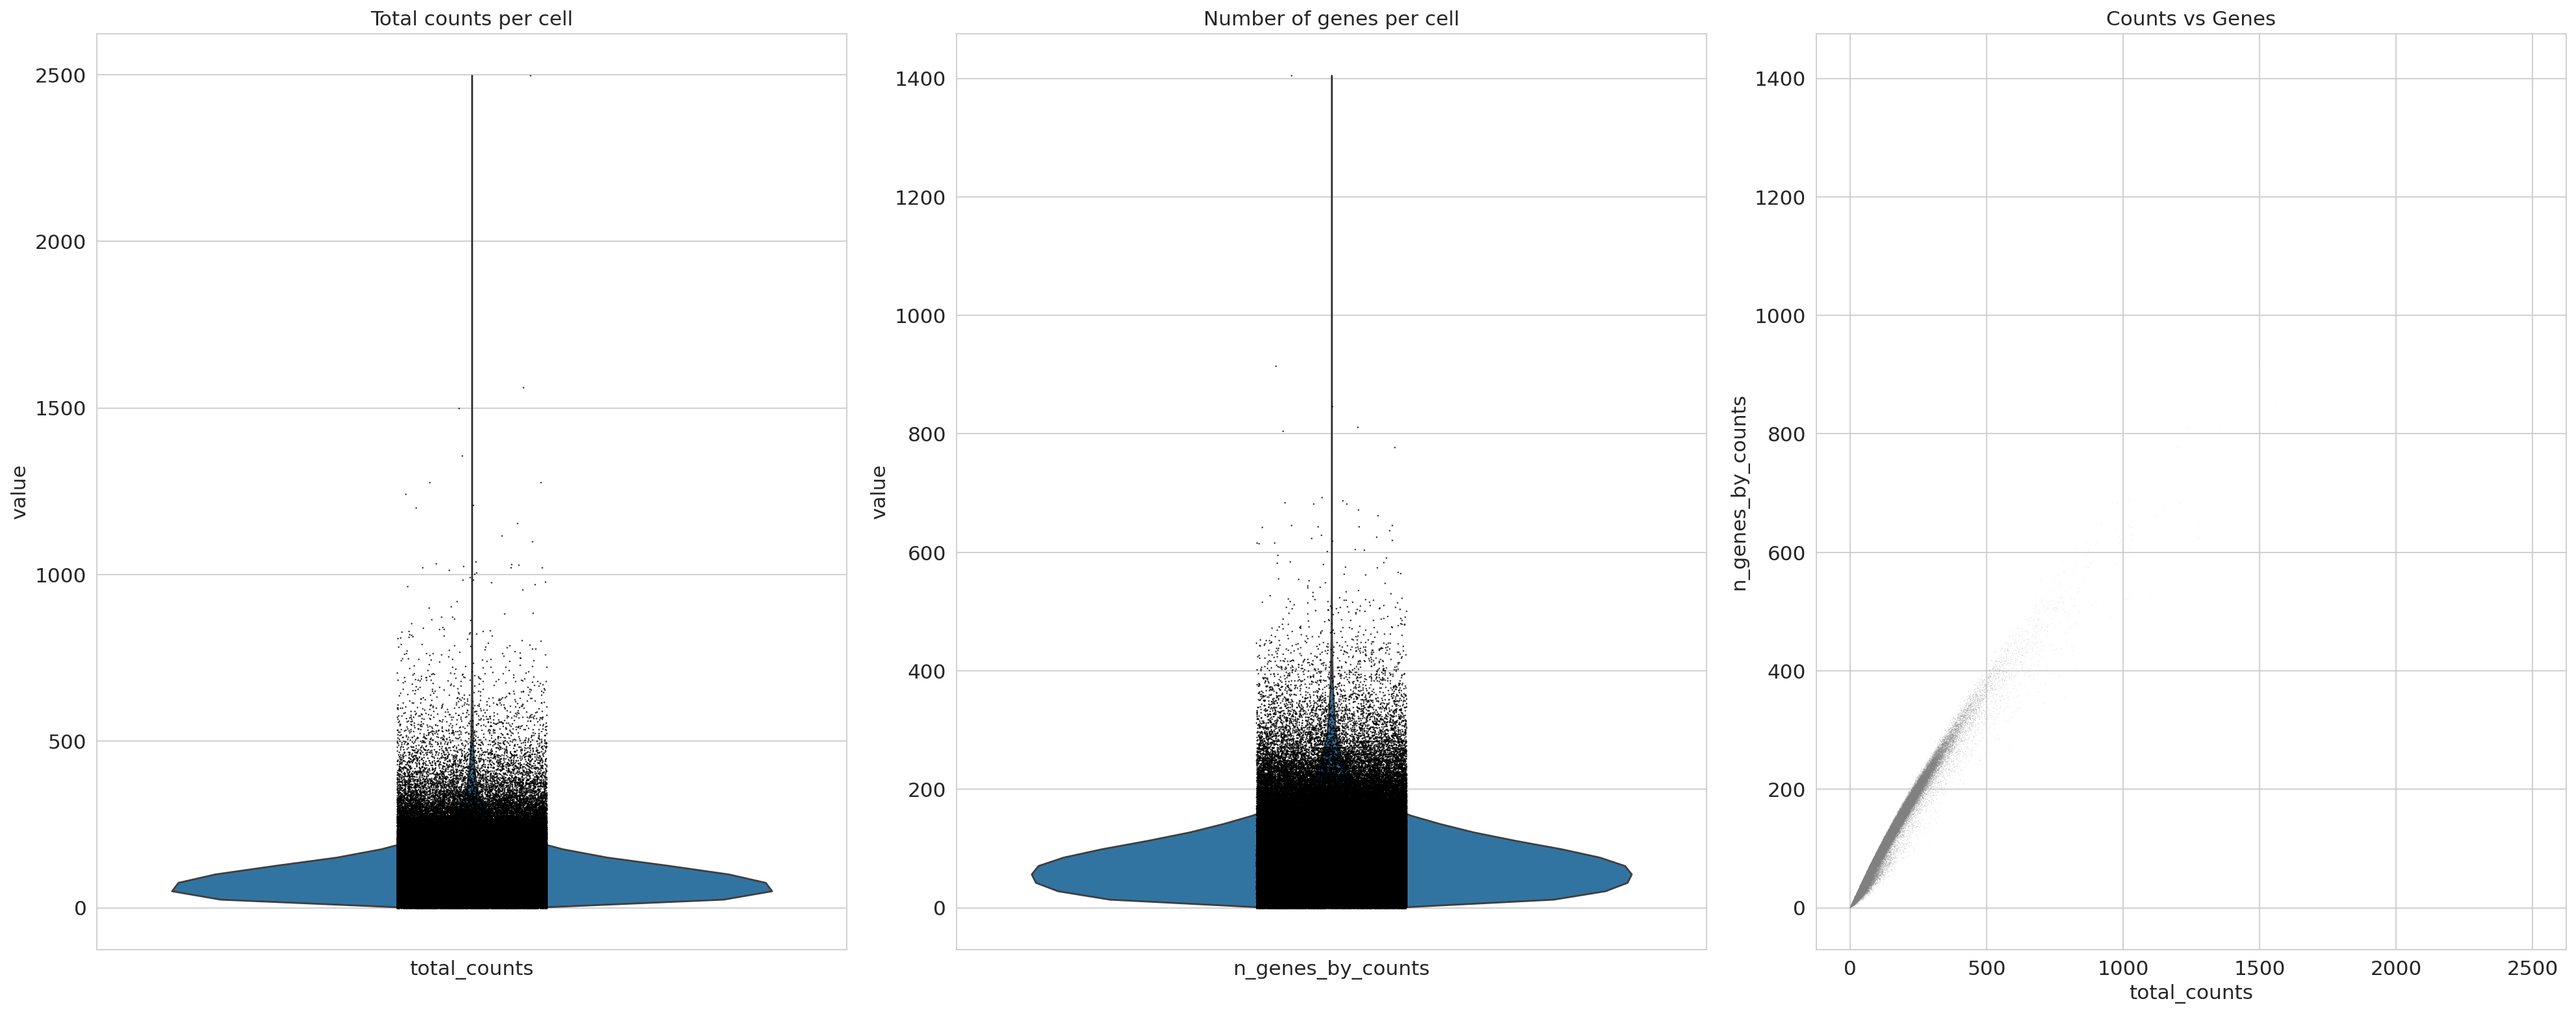

QC plots saved


In [11]:
# Visualize QC metrics
fig, axes = plt.subplots(1, 3, figsize=(25, 10))

# Total counts distribution
sc.pl.violin(adata, 'total_counts', ax=axes[0], show=False)
axes[0].set_title('Total counts per cell')
# Number of genes distribution
sc.pl.violin(adata, 'n_genes_by_counts', ax=axes[1], show=False)
axes[1].set_title('Number of genes per cell')

# Scatter plots
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', ax=axes[2], show=False)
axes[2].set_title('Counts vs Genes')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'qc_metrics_before_filtering.png', dpi=300, bbox_inches='tight')
plt.show()

print("QC plots saved")

## 4. Filtering

In [ ]:
import numpy as np

print(f"Before filtering:")
print(f"  Number of cells: {adata.n_obs}")
print(f"  Number of genes: {adata.n_vars}")

# Drop Xenium control probes (NegControl*, UnassignedCodeword, Antisense, BLANK)
# before QC filtering so they do not contaminate downstream statistics.
control_mask = adata.var_names.str.match(
    r"^(NegControlProbe_|UnassignedCodeword_|NegControlCodeword_|antisense_|BLANK_)",
    case=False,
)
if control_mask.any():
    print(f"  Dropping {int(control_mask.sum())} control probes")
    adata = adata[:, ~control_mask].copy()

# Lower bounds are absolute (sanity floor for noise / segmentation artifacts).
sc.pp.filter_cells(adata, min_genes=MIN_GENES)
sc.pp.filter_cells(adata, min_counts=MIN_COUNTS)

# Upper bound is DENSITY-BASED, not absolute counts. In FFPE Xenium cell_area
# varies 5-10x across cell types (acinar huge, T-cells tiny) and Spearman
# (total_counts, cell_area) ≈ 0.78 in this dataset. An absolute counts cap
# therefore predominantly drops large *healthy* cells (acinar/ductal/large
# epithelial), not unhealthy ones — 88% of cells removed by `counts > q98`
# have normal counts/area density. Switching to density-based upper filter
# preserves big healthy cells and drops actual outlier-density cells
# (likely doublets / segmentation merges).
density = (
    adata.obs["total_counts"].astype(np.float64)
    / np.maximum(adata.obs["cell_area"].astype(np.float64), 1.0)
)
density_cutoff = float(np.quantile(density, MAX_COUNTS_QUANTILE))
abs_counts_p98 = float(np.quantile(adata.obs["total_counts"], MAX_COUNTS_QUANTILE))
print(f"  Adaptive density cutoff = {density_cutoff:.3f} (counts/area, q={MAX_COUNTS_QUANTILE})")
print(f"  (For comparison: absolute counts q{int(MAX_COUNTS_QUANTILE*100)} = {abs_counts_p98:.0f})")
keep_density = (density <= density_cutoff).to_numpy()
n_drop_density = int((~keep_density).sum())
print(f"  Dropping {n_drop_density:,} cells by density>q{int(MAX_COUNTS_QUANTILE*100)} "
      f"(was {int((adata.obs['total_counts']>abs_counts_p98).sum()):,} by absolute counts)")
adata = adata[keep_density].copy()

sc.pp.filter_genes(adata, min_cells=MIN_CELLS)

print(f"\nAfter filtering:")
print(f"  Number of cells: {adata.n_obs}")
print(f"  Number of genes: {adata.n_vars}")


In [ ]:
# Overlay before+after histograms on the same axes so the actual filter
# effect is visible. Step-style histograms avoid bar-clipping artifacts.
n_before = len(_pre_filter_qc)
n_after = adata.n_obs
n_dropped = n_before - n_after
pct_dropped = 100.0 * n_dropped / max(n_before, 1)

fig, axs = plt.subplots(1, 4, figsize=(25, 6))

def _overlay(ax, before, after, title):
    sns.histplot(before, kde=False, ax=ax, color="#888888", alpha=0.45,
                 element="step", linewidth=1.5, stat="count",
                 label=f"before ({n_before:,})")
    sns.histplot(after, kde=False, ax=ax, color="#1f77b4", alpha=0.75,
                 element="step", linewidth=1.5, stat="count",
                 label=f"after ({n_after:,})")
    ax.set_title(title)
    ax.legend(loc="upper right")

_overlay(axs[0], _pre_filter_qc["total_counts"], adata.obs["total_counts"],
         "Total transcripts per cell")
_overlay(axs[1], _pre_filter_qc["n_genes_by_counts"], adata.obs["n_genes_by_counts"],
         "Unique transcripts per cell")
_overlay(axs[2], _pre_filter_qc["cell_area"], adata.obs["cell_area"],
         "Area of segmented cells")
_overlay(axs[3],
         _pre_filter_qc["nucleus_area"] / _pre_filter_qc["cell_area"],
         adata.obs["nucleus_area"] / adata.obs["cell_area"],
         "Nucleus ratio")

fig.suptitle(f"QC histograms: dropped {n_dropped:,} cells ({pct_dropped:.1f}%) "
             f"by min/max filters + density q98", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'qc_histo_after_filtering.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Overlay before+after as violin (with shared baseline) + scatter colored
# by kept/dropped status. Replaces the previous near-identical "before" /
# "after" pair.
import pandas as _pd

n_before = len(_pre_filter_qc)
n_after = adata.n_obs
n_dropped = n_before - n_after

_kept = adata.obs.index
_pre_total = _pre_filter_qc["total_counts"].copy()
_pre_genes = _pre_filter_qc["n_genes_by_counts"].copy()
_status_pre = _np.where(_pre_filter_qc.index.isin(_kept), "kept", "dropped") \
    if "_np" in dir() else None
import numpy as _np2
_status_pre = _np2.where(_pre_filter_qc.index.isin(_kept), "kept", "dropped")

fig, axes = plt.subplots(1, 3, figsize=(25, 10))

# Violin: before vs after for total_counts
df_tc = _pd.concat([
    _pd.DataFrame({"value": _pre_total, "phase": "before"}),
    _pd.DataFrame({"value": adata.obs["total_counts"].values, "phase": "after"}),
], ignore_index=True)
sns.violinplot(data=df_tc, x="phase", y="value", ax=axes[0], inner="quartile",
               palette={"before": "#888888", "after": "#1f77b4"}, cut=0)
axes[0].set_title(f"Total counts per cell\nbefore={n_before:,}  after={n_after:,}")

# Violin: before vs after for n_genes
df_ng = _pd.concat([
    _pd.DataFrame({"value": _pre_genes, "phase": "before"}),
    _pd.DataFrame({"value": adata.obs["n_genes_by_counts"].values, "phase": "after"}),
], ignore_index=True)
sns.violinplot(data=df_ng, x="phase", y="value", ax=axes[1], inner="quartile",
               palette={"before": "#888888", "after": "#1f77b4"}, cut=0)
axes[1].set_title(f"Genes per cell\nbefore={n_before:,}  after={n_after:,}")

# Scatter: counts vs genes, dropped (red) vs kept (blue)
import numpy as _np3
_idx = _np3.random.default_rng(0).choice(n_before, size=min(150_000, n_before), replace=False)
_sub_pre = _pre_filter_qc.iloc[_idx]
_sub_status = _status_pre[_idx]
axes[2].scatter(_sub_pre["total_counts"][_sub_status == "kept"],
                _sub_pre["n_genes_by_counts"][_sub_status == "kept"],
                s=3, c="#1f77b4", alpha=0.4, linewidths=0,
                label=f"kept ({(_sub_status == 'kept').sum():,})")
axes[2].scatter(_sub_pre["total_counts"][_sub_status == "dropped"],
                _sub_pre["n_genes_by_counts"][_sub_status == "dropped"],
                s=4, c="#d62728", alpha=0.7, linewidths=0,
                label=f"dropped ({(_sub_status == 'dropped').sum():,})")
axes[2].set_xlabel("total_counts"); axes[2].set_ylabel("n_genes_by_counts")
axes[2].set_title(f"Counts vs genes (subsample {len(_idx):,} cells)")
axes[2].legend(loc="best", framealpha=0.9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'qc_metrics_after_filtering.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"QC plots saved (dropped {n_dropped:,} cells, kept {n_after:,})")


## 5. Normalization and Log-Transformation

In [ ]:
_audit_csv = (str(_repo / "data/processed/panel_audit.csv")
              if _TISSUE == "pancreas"
              else str(_repo / f"data/processed/panel_audit_{_TISSUE}.csv"))
# Trimmed for the scANVI pipeline (2026-06-02): this cell now produces ONLY the
# scANVI-relevant outputs - raw counts layer, normalize_total+log1p lognorm layer,
# and the audit-aware panel_for_scoring / panel_for_embedding masks + donor_sex tag.
# The vestigial flat-path steps (HVG, scale, global PCA / neighbors / UMAP, leiden_1.5)
# were removed: hierarchical_phenotype.py trains scANVI on layers['counts'] over
# var['panel_for_embedding'] and computes its own latent / per-lineage sub-PCA / UMAP,
# so none of those were consumed downstream. finalize_panel.py stamps the remaining
# subpanel_<L> / celltype_panel / embedding_panel masks after this notebook runs.

# --- Set panel masks + donor_sex inline from panel_audit.csv if missing, so a
# fresh-from-zarr run is self-contained.
if 'panel_for_embedding' not in adata.var.columns:
    import pandas as _pd
    _audit = _pd.read_csv(_audit_csv)
    _nonsex = set(_audit.loc[(_audit['exclude_recommended']=='yes') &
                              (_audit['category']!='sex_chromosome'), 'gene'])
    _sex_chrom = set(_audit.loc[_audit['category']=='sex_chromosome', 'gene'])
    adata.var['panel_for_scoring'] = ~adata.var_names.isin(_nonsex)
    adata.var['panel_for_embedding'] = (~adata.var_names.isin(_nonsex)
                                          & ~adata.var_names.isin(_sex_chrom))
    print(f"panel_for_scoring: {int(adata.var['panel_for_scoring'].sum()):,} kept")
    print(f"panel_for_embedding: {int(adata.var['panel_for_embedding'].sum()):,} kept")

if 'donor_sex' not in adata.obs.columns:
    _LOG_DETECT = float(np.log1p(1.0))
    _sex_genes = [g for g in ('KDM5D', 'DDX3Y') if g in adata.var_names]
    if _sex_genes:
        _layer = adata.layers['lognorm'] if 'lognorm' in adata.layers else adata.X
        _n_max = 0
        for _g in _sex_genes:
            _i = adata.var_names.get_loc(_g)
            _col = _layer[:, _i]
            if hasattr(_col, 'toarray'):
                _col = _col.toarray()
            _col = np.asarray(_col).ravel()
            _n_max = max(_n_max, int((_col >= _LOG_DETECT).sum()))
        _sex = 'male' if _n_max / max(adata.n_obs, 1) >= 0.02 else 'female'
    else:
        _sex = 'unknown'
    import pandas as _pd
    adata.obs['donor_sex'] = _pd.Categorical([_sex]*adata.n_obs,
                                               categories=['female','male','unknown'])
    print(f"donor_sex tag: {_sex}")

# Raw counts are the scVI/scANVI + DE input; lognorm is the marker-scoring scale.
adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
adata.layers['lognorm'] = adata.X.copy()
print("normalize_total + log1p applied; layers['counts'] + layers['lognorm'] saved.")


## 8. Save Preprocessed Data

In [ ]:
output_file = OUTPUT_DIR / f"{SAMPLE_ID}_preprocessed.h5ad"
adata.write_h5ad(output_file)

print(f"\nPreprocessed data saved to: {output_file}")
print(f"Final dataset shape: {adata.shape}")
print(f"\nLayers available:")
print(list(adata.layers.keys()))
print(f"\nObsm keys (embeddings):")
print(list(adata.obsm.keys()))

## 9. Summary Statistics

In [ ]:
summary = {
    'Sample': SAMPLE_ID,
    'Total cells': adata.n_obs,
    'Total genes': adata.n_vars,
    'Mean counts per cell':   float(adata.obs['total_counts'].mean()),
    'Median counts per cell': float(adata.obs['total_counts'].median()),
    'Mean genes per cell':    float(adata.obs['n_genes_by_counts'].mean()),
    'Median genes per cell':  float(adata.obs['n_genes_by_counts'].median()),
}

summary_df = pd.DataFrame([summary]).T
summary_df.columns = ['Value']

print("\n=== Preprocessing Summary ===")
print(summary_df)

summary_csv = OUTPUT_DIR / f"{SAMPLE_ID}_preprocessing_summary.csv"
summary_df.to_csv(summary_csv)
print(f"\nSummary saved to: {summary_csv}")


---

## Next Steps

The preprocessed data is ready for:
1. **Cell type annotation** (02_phenotyping.ipynb)
2. **Spatial analysis** (03_spatial_analysis.ipynb)
3. **Group comparisons** (04_group_comparisons.ipynb)
4. **Integration with Phenocycler data** (06_xenium_phenocycler_integration.ipynb)